# ETHEREUM GUARD — EDA & Graph Statistics

**Mục đích:** Khám phá dữ liệu giao dịch Ethereum, chất lượng dữ liệu, nhãn, đặc trưng tài khoản, cấu trúc đồ thị và hành vi thời gian. Notebook phục vụ TV1-07 và cung cấp số liệu cho Chương 3 (Dataset) và Chương 4 (Feature & Graph Construction).

> Chạy notebook từ thư mục gốc `ethereum-guard/`. Notebook chỉ đọc dữ liệu hiện có, không chạy lại ingestion, split, feature engineering hay graph builder. Sau khi rebuild TV1-04/TV1-05, hãy chạy lại toàn bộ notebook để cập nhật kết quả.


In [21]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

PROJECT_ROOT = Path.cwd()

# Nếu Jupyter đang chạy từ notebooks/, lùi lên thư mục gốc
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "data").exists():
    raise FileNotFoundError(
        f"Không tìm thấy thư mục data/. Current directory: {Path.cwd()}"
    )

print("Project root:", PROJECT_ROOT)

DATA = PROJECT_ROOT / "data"
RESULTS = PROJECT_ROOT / "artifacts" / "results"

TX_DIR = DATA / "processed" / "transactions"
FEATURE_DIR = DATA / "processed" / "features"
GRAPH_DIR = DATA / "processed" / "graphs"
SPLIT_DIR = DATA / "processed" / "splits"

SPLITS = ["train", "val", "test"]

plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

print("Project root:", PROJECT_ROOT)
print("Transaction files:", len(list(TX_DIR.glob("*.parquet"))))

Project root: c:\Users\minhk\Downloads\ethereum-guard
Project root: c:\Users\minhk\Downloads\ethereum-guard
Transaction files: 4


## 1. Dataset overview

Nguồn giao dịch là bốn Parquet mẫu đã qua ingestion. Các snapshot và feature tables được đọc từ đầu ra TV1 đã tạo. Các con số trong notebook phản ánh đúng phạm vi dữ liệu mẫu hiện có, không đại diện cho toàn bộ lịch sử Ethereum.

In [22]:
audit = json.loads((RESULTS / "vnegi10_sample_audit.json").read_text(encoding="utf-8"))
ingestion = json.loads((RESULTS / "ingestion_report.json").read_text(encoding="utf-8"))
split_report = json.loads((RESULTS / "split_report.json").read_text(encoding="utf-8"))
address_report = json.loads((RESULTS / "address_registry_report.json").read_text(encoding="utf-8"))
feature_report = json.loads((RESULTS / "feature_report.json").read_text(encoding="utf-8"))
graph_report = json.loads((RESULTS / "graph_report.json").read_text(encoding="utf-8"))
leakage_report_path = RESULTS / "leakage_audit_report.json"
leakage_report = (
    json.loads(leakage_report_path.read_text(encoding="utf-8"))
    if leakage_report_path.exists() else None
)

overview = pd.DataFrame([
    ("Transaction rows", split_report["input"]["total_transactions"]),
    ("Unique addresses", address_report["summary"]["unique_addresses_in_sample"]),
    ("Known phishing addresses found", address_report["summary"]["known_phishing_addresses_found_in_sample"]),
    ("Unlabeled addresses", address_report["summary"]["unlabeled_addresses_in_sample"]),
    ("Transactions involving known phishing addresses", address_report["summary"]["transactions_involving_known_phishing_addresses"]),
    ("Transaction files", len(split_report["input"]["files"])),
], columns=["Metric", "Value"])
display(overview)

,Metric,Value
0,Transaction rows,2618597
1,Unique addresses,1791594
2,Known phishing addresses found,125
3,Unlabeled addresses,1791469
4,Transactions involving known phishing addresses,301
5,Transaction files,4


## 2. Data quality assessment

Kiểm tra trên toàn bộ bốn transaction Parquet: số dòng, null, duplicate transaction hash, phân phối trạng thái thành công và khoảng thời gian. Các file được đọc lần lượt để hạn chế tăng bộ nhớ đột biến.

In [23]:
tx_files = sorted(TX_DIR.glob("*.parquet"))
if not tx_files:
    raise FileNotFoundError(f"Không tìm thấy Parquet trong {TX_DIR}")

# Chỉ đọc các cột cần cho EDA để giảm RAM.
wanted_columns = [
    "timestamp", "value_eth", "gas_used", "gas_price", "success",
    "from_address", "to_address", "transaction_hash"
]

quality_rows = []
tx_frames_for_eda = []

for path in tx_files:
    import pyarrow.parquet as pq
    available = pq.ParquetFile(path).schema.names
    selected = [c for c in wanted_columns if c in available]
    df = pd.read_parquet(path, columns=selected)
    tx_frames_for_eda.append(df)
    quality_rows.append({
        "file": path.name,
        "rows": len(df),
        "null_from": int(df["from_address"].isna().sum()) if "from_address" in df else None,
        "null_to": int(df["to_address"].isna().sum()) if "to_address" in df else None,
        "null_timestamp": int(df["timestamp"].isna().sum()) if "timestamp" in df else None,
        "duplicate_hash": int(df["transaction_hash"].duplicated().sum()) if "transaction_hash" in df else None,
    })

quality_df = pd.DataFrame(quality_rows)
display(quality_df)
print("Total rows:", quality_df["rows"].sum())
print("Total null receivers:", quality_df["null_to"].sum())


,file,rows,null_from,null_to,null_timestamp,duplicate_hash
0,ethereum__transactions__02640567_to_02765542.p...,37442,0,140,0,0
1,ethereum__transactions__14666567_to_14791542.p...,909819,0,637,0,0
2,ethereum__transactions__18416567_to_18541542.p...,753668,0,723,0,0
3,ethereum__transactions__19416567_to_19541542.p...,917668,0,615,0,0


Total rows: 2618597
Total null receivers: 2115


Timestamp range: 2016-11-17 00:51:33+00:00 to 2024-03-29 18:49:23+00:00


,transactions
success,
False,56839
True,2561758


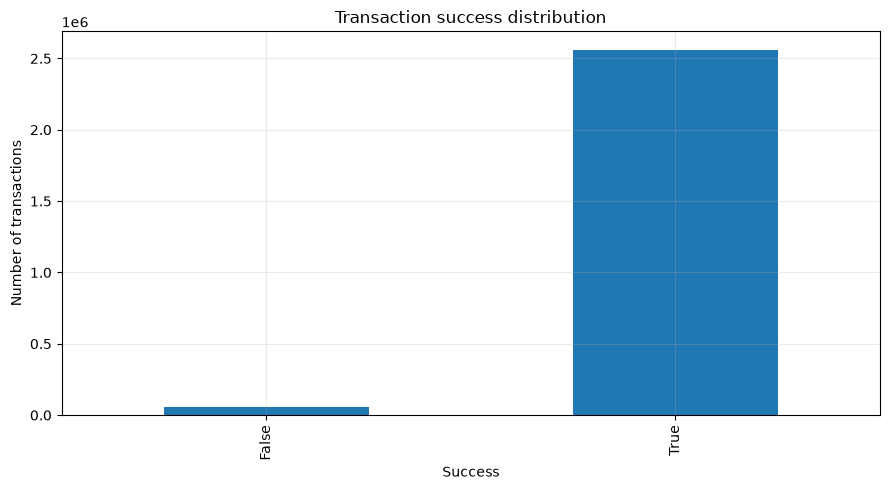

In [24]:
tx = pd.concat(tx_frames_for_eda, ignore_index=True)
del tx_frames_for_eda

if "timestamp" in tx.columns:
    tx["timestamp_utc"] = pd.to_datetime(tx["timestamp"], unit="s", utc=True, errors="coerce")
    print("Timestamp range:", tx["timestamp_utc"].min(), "to", tx["timestamp_utc"].max())

if "success" in tx.columns:
    success_counts = tx["success"].value_counts(dropna=False).sort_index()
    display(success_counts.rename_axis("success").to_frame("transactions"))
    success_counts.plot(kind="bar", title="Transaction success distribution")
    plt.xlabel("Success")
    plt.ylabel("Number of transactions")
    plt.tight_layout()
    plt.show()

### 2.1 Missing receiver

`to_address` có thể null trong giao dịch tạo hợp đồng (contract creation). Không tự động loại các giao dịch này khỏi thống kê giao dịch thô; tuy nhiên, chúng không tạo được cạnh sender-to-receiver thông thường nếu thiếu đích nhận.

In [25]:
null_to = int(tx["to_address"].isna().sum())
total_tx = len(tx)
print(f"Null to_address: {null_to:,} / {total_tx:,} ({null_to / total_tx:.4%})")

Null to_address: 2,115 / 2,618,597 (0.0808%)


## 3. Label distribution and limitations

Nhãn ở cấp địa chỉ: `1` = địa chỉ phishing đã biết từ MDBChain; `-1` = chưa gán nhãn; `0` không được gán vì chưa có nguồn xác minh normal. Không diễn giải `-1` thành normal.

,addresses
label,
-1,1791469
1,125


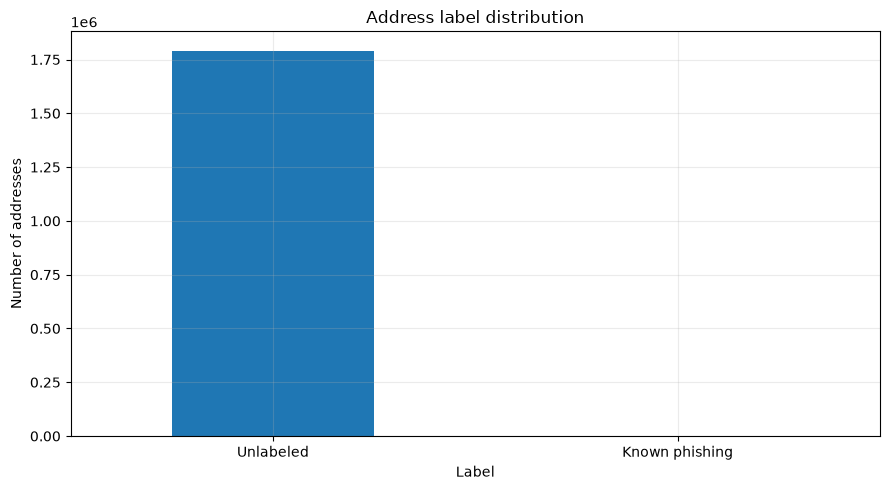

Verified normal labels: 0
Known phishing labels: 125
Unlabeled: 1791469


In [26]:
registry_path = DATA / "processed" / "address_registry" / "address_labels.parquet"
registry = pd.read_parquet(registry_path)

label_counts = registry["label"].value_counts(dropna=False).sort_index()
display(label_counts.rename_axis("label").to_frame("addresses"))

label_names = {-1: "Unlabeled", 0: "Verified normal", 1: "Known phishing"}
plot_labels = label_counts.rename(index=label_names)
plot_labels.plot(kind="bar", title="Address label distribution")
plt.xlabel("Label")
plt.ylabel("Number of addresses")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Verified normal labels:", int((registry["label"] == 0).sum()))
print("Known phishing labels:", int((registry["label"] == 1).sum()))
print("Unlabeled:", int((registry["label"] == -1).sum()))

## 4. Transaction behavior analysis

Phân tích giá trị ETH, gas và hoạt động theo thời gian. Giá trị giao dịch được đọc từ `value_eth` nếu có; các biểu đồ giá trị thường dùng thang log để quan sát phần đuôi phân phối dài. Đây là mô tả phân phối, không phải kết luận giao dịch lớn là gian lận.

count    2.618597e+06
mean     2.293472e+00
std      1.845003e+02
min      0.000000e+00
50%      0.000000e+00
90%      4.418864e-01
95%      1.201408e+00
99%      1.003573e+01
max      2.000000e+05
Name: value_eth, dtype: float64


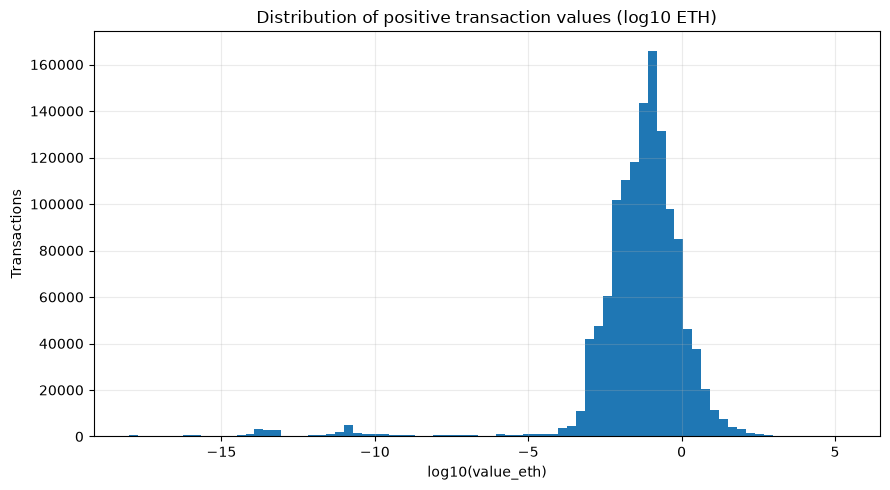


gas_used summary


,gas_used
count,2.618597e+06
mean,8.789179e+04
std,2.153020e+05
min,1.356000e+04
50%,4.610900e+04
90%,1.913670e+05
95%,2.547220e+05
99%,5.702028e+05
max,2.853307e+07


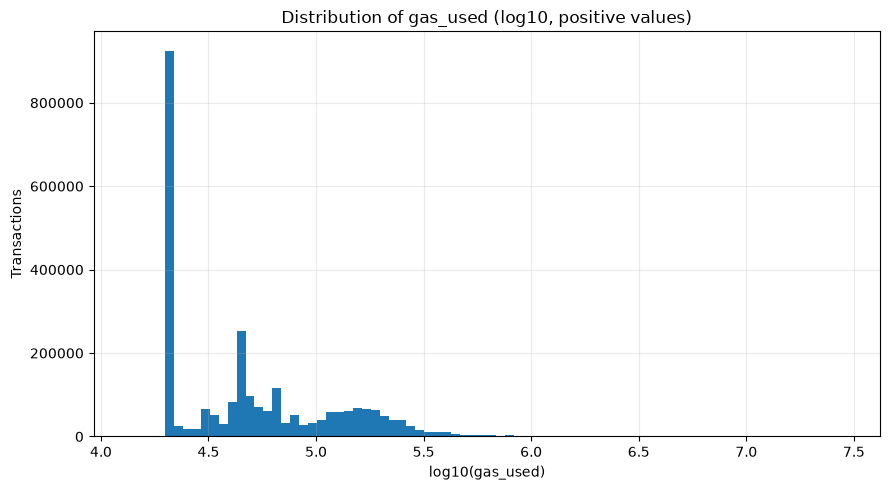


gas_price summary


,gas_price
count,2.618597e+06
mean,5.329577e+10
std,2.267547e+11
min,0.000000e+00
50%,3.380528e+10
90%,7.617779e+10
95%,1.068061e+11
99%,2.880000e+11
max,3.255756e+13


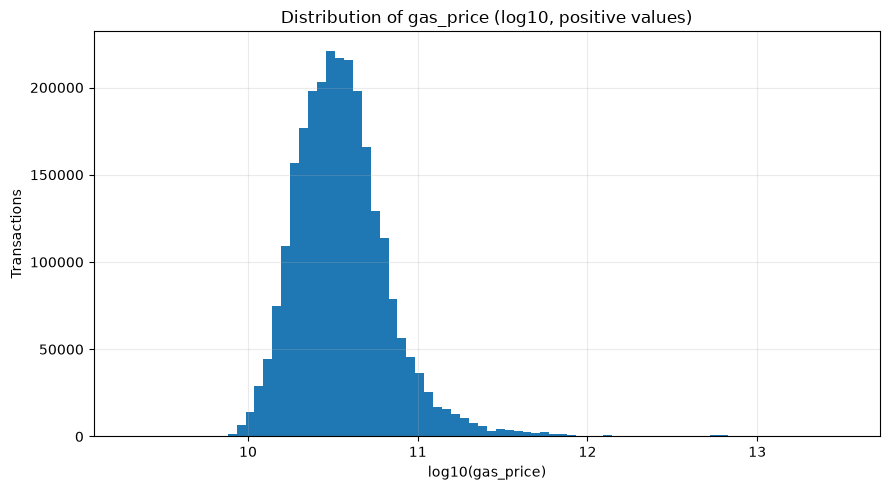

In [27]:
if "value_eth" in tx.columns:
    values = pd.to_numeric(tx["value_eth"], errors="coerce")
    values = values.replace([np.inf, -np.inf], np.nan).dropna()
    print(values.describe(percentiles=[.5, .9, .95, .99]))
    positive_log = np.log10(values[values > 0])
    plt.figure()
    plt.hist(positive_log, bins=80)
    plt.title("Distribution of positive transaction values (log10 ETH)")
    plt.xlabel("log10(value_eth)")
    plt.ylabel("Transactions")
    plt.tight_layout()
    plt.show()
else:
    print("Không có value_eth trong transaction table; bỏ qua biểu đồ giá trị ETH.")

for col in ["gas_used", "gas_price"]:
    if col in tx.columns:
        series = pd.to_numeric(tx[col], errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
        print(f"\n{col} summary")
        display(series.describe(percentiles=[.5, .9, .95, .99]).to_frame())
        positive = series[series > 0]
        if len(positive):
            plt.figure()
            plt.hist(np.log10(positive), bins=80)
            plt.title(f"Distribution of {col} (log10, positive values)")
            plt.xlabel(f"log10({col})")
            plt.ylabel("Transactions")
            plt.tight_layout()
            plt.show()

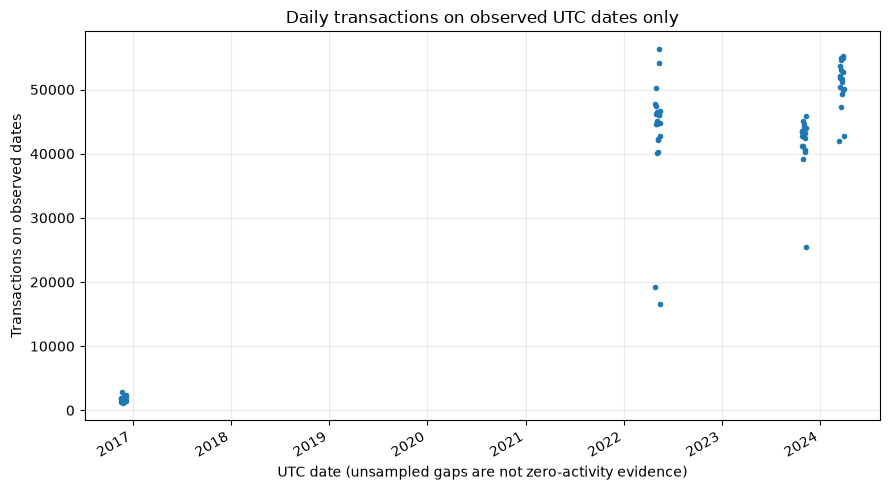

Observed UTC dates: 78


,transactions_on_observed_days
count,78.000000
mean,33571.756410
std,20461.879502
min,1189.000000
50%,43156.500000
90%,52805.500000
95%,54615.100000
99%,55478.850000
max,56322.000000


In [28]:
# Chỉ thống kê những ngày thực sự có giao dịch trong các mẫu đã thu thập.
# Không tự chèn các ngày không có dữ liệu thành 0 giao dịch.
if "timestamp_utc" in tx.columns:
    observed_daily_tx = (
        tx.dropna(subset=["timestamp_utc"])
          .assign(utc_date=lambda frame: frame["timestamp_utc"].dt.floor("D"))
          .groupby("utc_date")
          .size()
          .sort_index()
    )

    observed_daily_tx.plot(
        marker=".",
        linestyle="none",
        title="Daily transactions on observed UTC dates only"
    )
    plt.xlabel("UTC date (unsampled gaps are not zero-activity evidence)")
    plt.ylabel("Transactions on observed dates")
    plt.tight_layout()
    plt.show()

    print("Observed UTC dates:", len(observed_daily_tx))
    display(
        observed_daily_tx.describe(
            percentiles=[.5, .9, .95, .99]
        ).to_frame("transactions_on_observed_days")
    )

## 5. Node feature analysis

Sau khi chạy TV1-04 và TV1-05, mỗi node có 25 đặc trưng: 12 tabular, 6 graph topology và 7 temporal statistics. Lưu ý: `features/{split}/nodes.parquet` là bảng trước graph enrichment; sáu graph features được ghi vào `graphs/{split}/nodes.parquet`. Trong `nodes.parquet`, 19 đặc trưng tabular/temporal đã được chuẩn hóa; sáu graph features được cập nhật sau graph building. Notebook khôi phục 19 đặc trưng bằng scaler tương ứng và đọc topology features từ PyG snapshot, sau đó ghép theo địa chỉ.


In [29]:
# Khai báo 25 đặc trưng theo đúng schemas.py.
feature_groups = {
    "Tabular (12)": [
        "total_eth_sent", "total_eth_received", "net_balance_diff",
        "avg_eth_sent", "max_eth_sent", "avg_eth_received", "max_eth_received",
        "tx_sent_count", "tx_recv_count", "sent_recv_ratio",
        "zero_val_tx_ratio", "failed_tx_ratio"
    ],
    "Graph topology (6)": [
        "in_degree", "out_degree", "unique_in_neighbors",
        "unique_out_neighbors", "neighbor_repeat_ratio", "local_ego_density"
    ],
    "Temporal statistics (7)": [
        "active_duration_hours", "tx_frequency_per_day", "mean_inter_tx_time",
        "std_inter_tx_time", "burstiness_index",
        "recent_volume_spike_ratio", "recent_tx_spike_ratio"
    ],
}

# Đọc Train node table. 19 cột tabular + temporal statistics đã được scale.
train_nodes = pd.read_parquet(FEATURE_DIR / "train" / "nodes.parquet")

# Khôi phục 19 đặc trưng về đơn vị gốc bằng scaler đã fit trên Train.
import joblib

feature_scaler_bundle = joblib.load(
    PROJECT_ROOT / "artifacts" / "scalers" / "feature_robust_scaler.joblib"
)
feature_scaler = feature_scaler_bundle["scaler"]
feature_scaler_columns = feature_scaler_bundle["columns"]

missing_scaled = [
    col for col in feature_scaler_columns
    if col not in train_nodes.columns
]
if missing_scaled:
    raise KeyError(f"Missing scaled feature columns: {missing_scaled}")

raw_19 = feature_scaler.inverse_transform(
    train_nodes[feature_scaler_columns].to_numpy(dtype=np.float64)
)
eda_features = train_nodes[["address"]].copy()
eda_features[feature_scaler_columns] = raw_19

# Sáu topology features được lưu trong PyG snapshot, không phải nodes.parquet.
train_graph = torch.load(
    GRAPH_DIR / "train" / "snapshot_train.pt",
    map_location="cpu",
    weights_only=False
)
graph_scaler_bundle = joblib.load(
    PROJECT_ROOT / "artifacts" / "scalers" / "graph_feature_scaler.joblib"
)
graph_scaler = graph_scaler_bundle["scaler"]
graph_scaler_columns = graph_scaler_bundle["columns"]

topology_scaled = train_graph.x_topo.detach().cpu().numpy()
topology_raw = graph_scaler.inverse_transform(topology_scaled)

snapshot_addresses = list(train_graph.addresses)
topology_frame = pd.DataFrame(topology_raw, columns=graph_scaler_columns)
topology_frame.insert(0, "address", snapshot_addresses)

# Ghép theo address để không phụ thuộc thứ tự dòng giữa hai file.
eda_features = eda_features.merge(
    topology_frame,
    on="address",
    how="left",
    validate="one_to_one"
)

feature_cols = [
    col
    for columns in feature_groups.values()
    for col in columns
]
missing = [col for col in feature_cols if col not in eda_features.columns]
if missing:
    raise KeyError(f"Missing EDA features: {missing}")

print("Train nodes:", len(eda_features))
print("Feature groups:")
for group, columns in feature_groups.items():
    print(f"{group}: {len(columns)}")
print("Total features:", len(feature_cols))
print("Missing values across 25 features:")
display(eda_features[feature_cols].isna().sum().to_frame("missing_count"))

for split in SPLITS:
    print(
        split,
        "nodes:", graph_report["splits"][split]["nodes"],
        "features:", graph_report["node_features"]
    )

Train nodes: 1016762
Feature groups:
Tabular (12): 12
Graph topology (6): 6
Temporal statistics (7): 7
Total features: 25
Missing values across 25 features:


,missing_count
total_eth_sent,0
total_eth_received,0
net_balance_diff,0
avg_eth_sent,0
max_eth_sent,0
avg_eth_received,0
max_eth_received,0
tx_sent_count,0
tx_recv_count,0
sent_recv_ratio,0


train nodes: 1016762 features: 25
val nodes: 1528608 features: 25
test nodes: 1791594 features: 25


In [30]:
feature_summary = eda_features[feature_cols].describe(
    percentiles=[.5, .9, .95, .99]
).T

display(feature_summary)

,count,mean,std,min,50%,90%,95%,99%,max
total_eth_sent,1016762.0,3.963668e+00,3.205538e+02,0.000000,0.0,0.449700,1.430000,1.090671e+01,1.696529e+05
total_eth_received,1016762.0,3.963662e+00,3.674861e+02,0.000000,0.0,0.233453,0.990902,7.462508e+00,2.035723e+05
net_balance_diff,1016762.0,-5.840287e-06,3.761553e+02,-101457.256476,0.0,0.199263,0.750000,6.000000e+00,1.911747e+05
avg_eth_sent,1016762.0,1.867597e+00,1.233476e+02,0.000000,0.0,0.320000,1.002003,7.401303e+00,5.330900e+04
max_eth_sent,1016762.0,2.749809e+00,1.801042e+02,0.000000,0.0,0.400000,1.234499,9.999528e+00,6.296669e+04
avg_eth_received,1016762.0,1.707058e+00,1.224340e+02,0.000000,0.0,0.205771,0.808705,5.561017e+00,5.760000e+04
max_eth_received,1016762.0,2.511086e+00,1.760549e+02,0.000000,0.0,0.213958,0.900000,6.295390e+00,6.296669e+04
tx_sent_count,1016762.0,1.451255e+00,4.192960e+01,0.000000,1.0,2.000000,3.000000,7.000000e+00,1.878800e+04
tx_recv_count,1016762.0,1.449821e+00,1.642793e+02,0.000000,0.0,1.000000,1.000000,6.000000e+00,1.276340e+05
sent_recv_ratio,1016762.0,1.923956e+00,2.411333e+01,0.000008,2.0,3.000000,3.000000,7.000000e+00,1.878900e+04


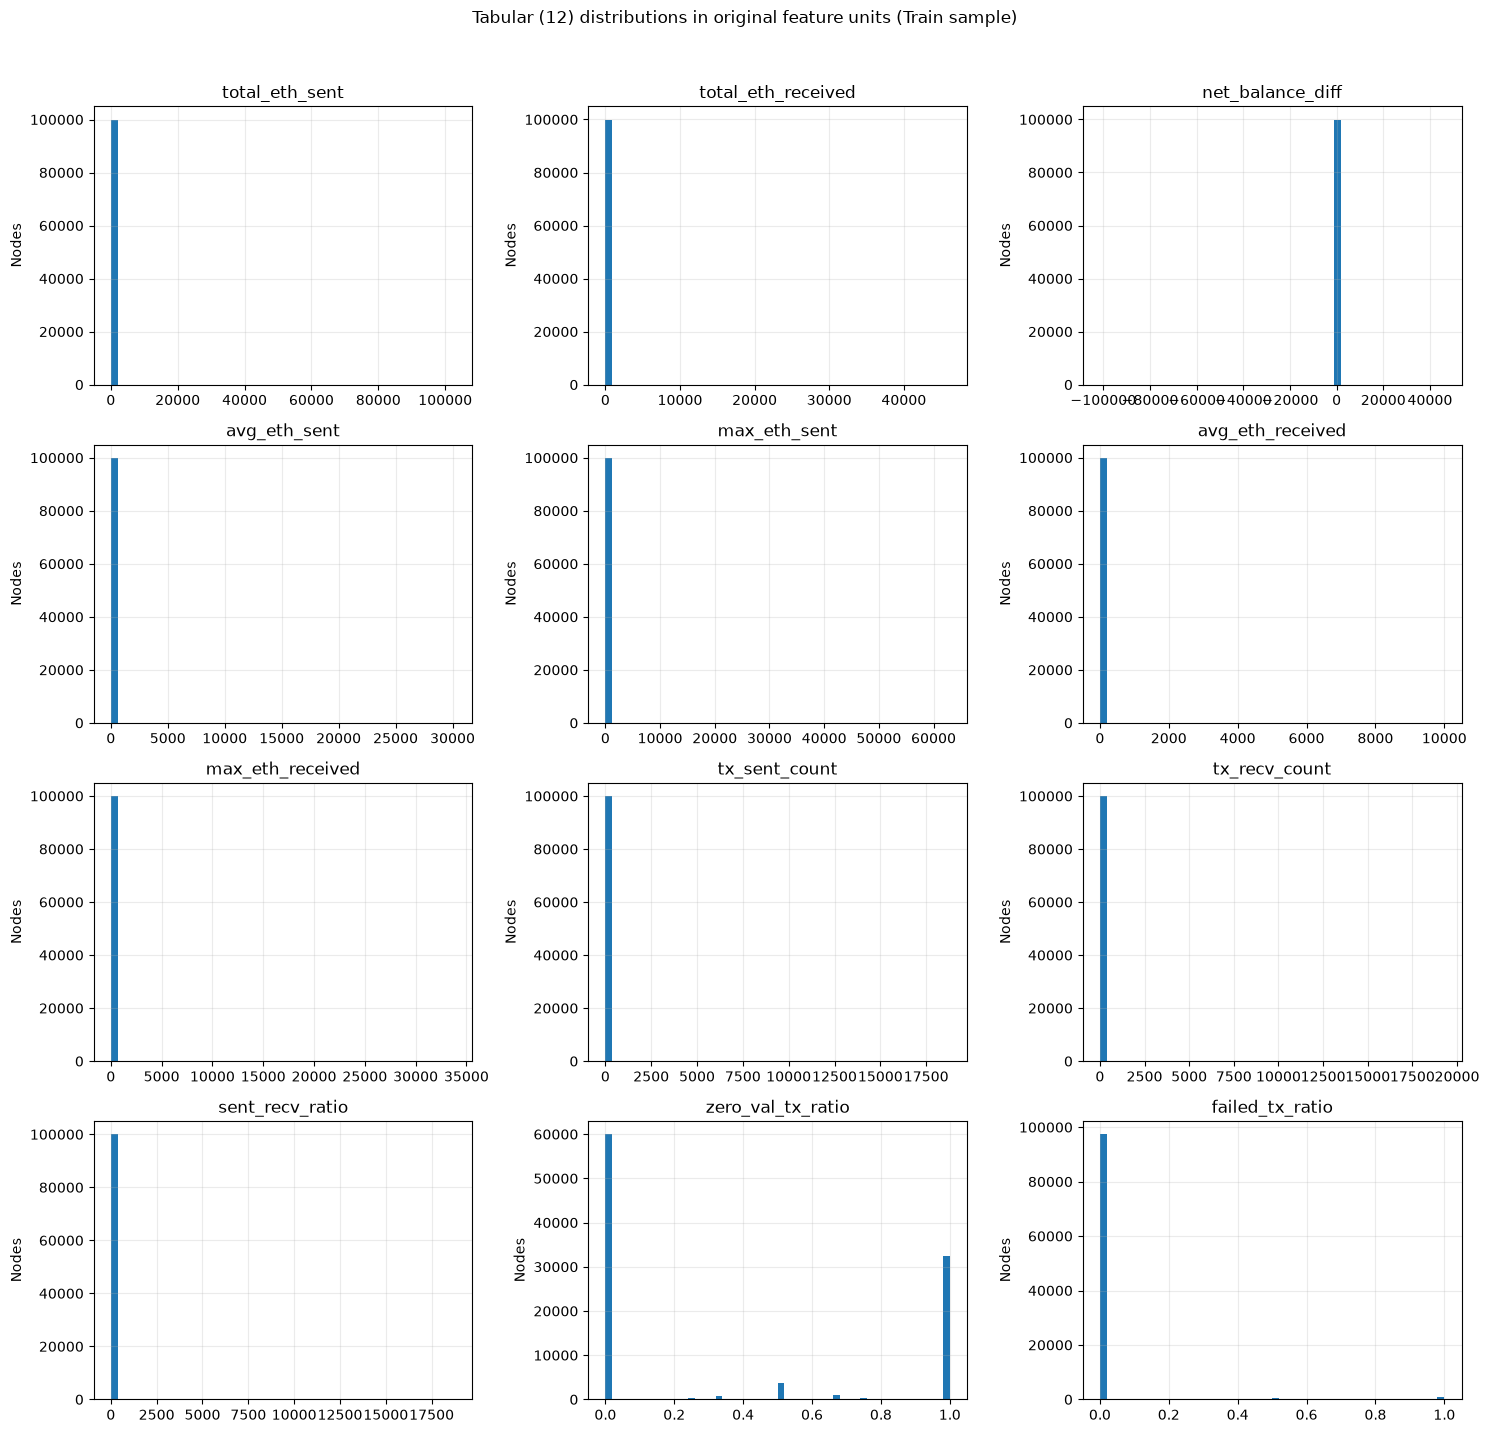

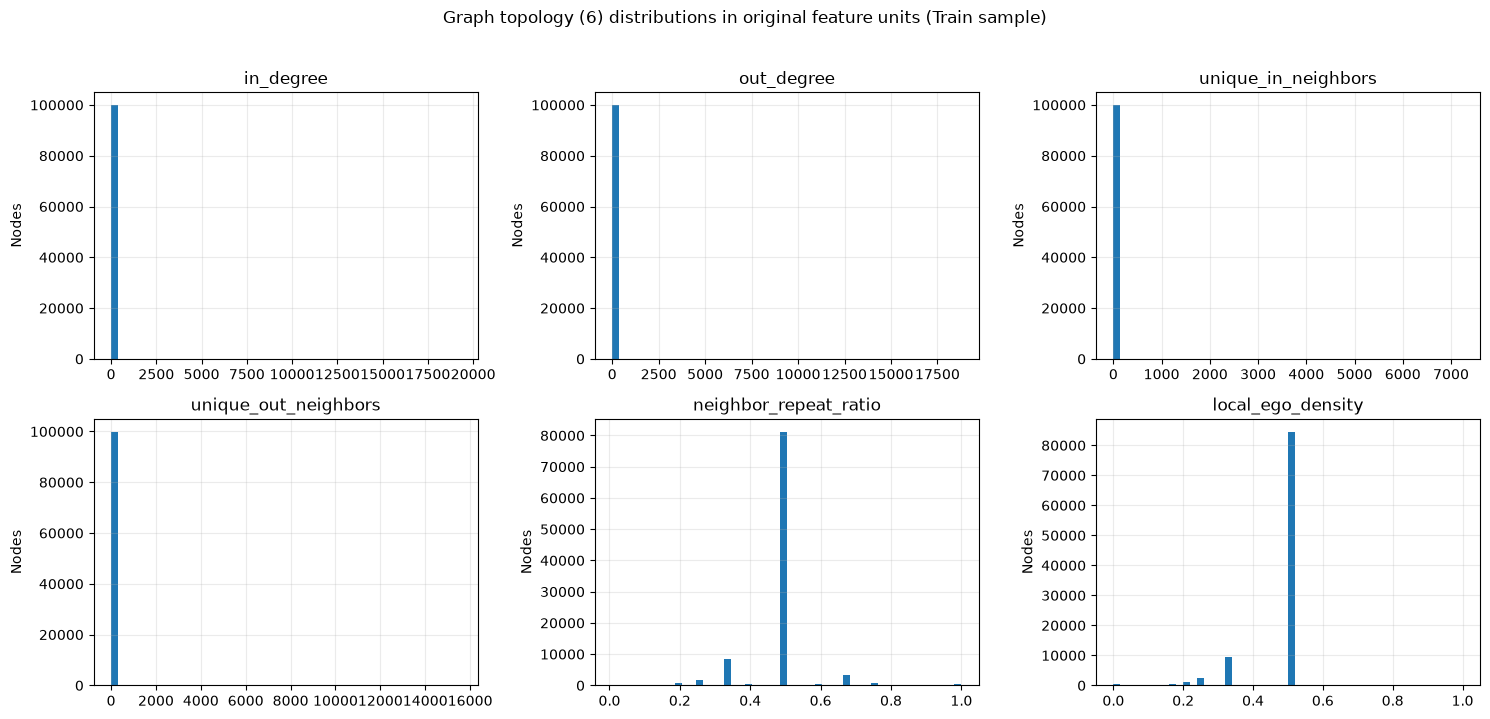

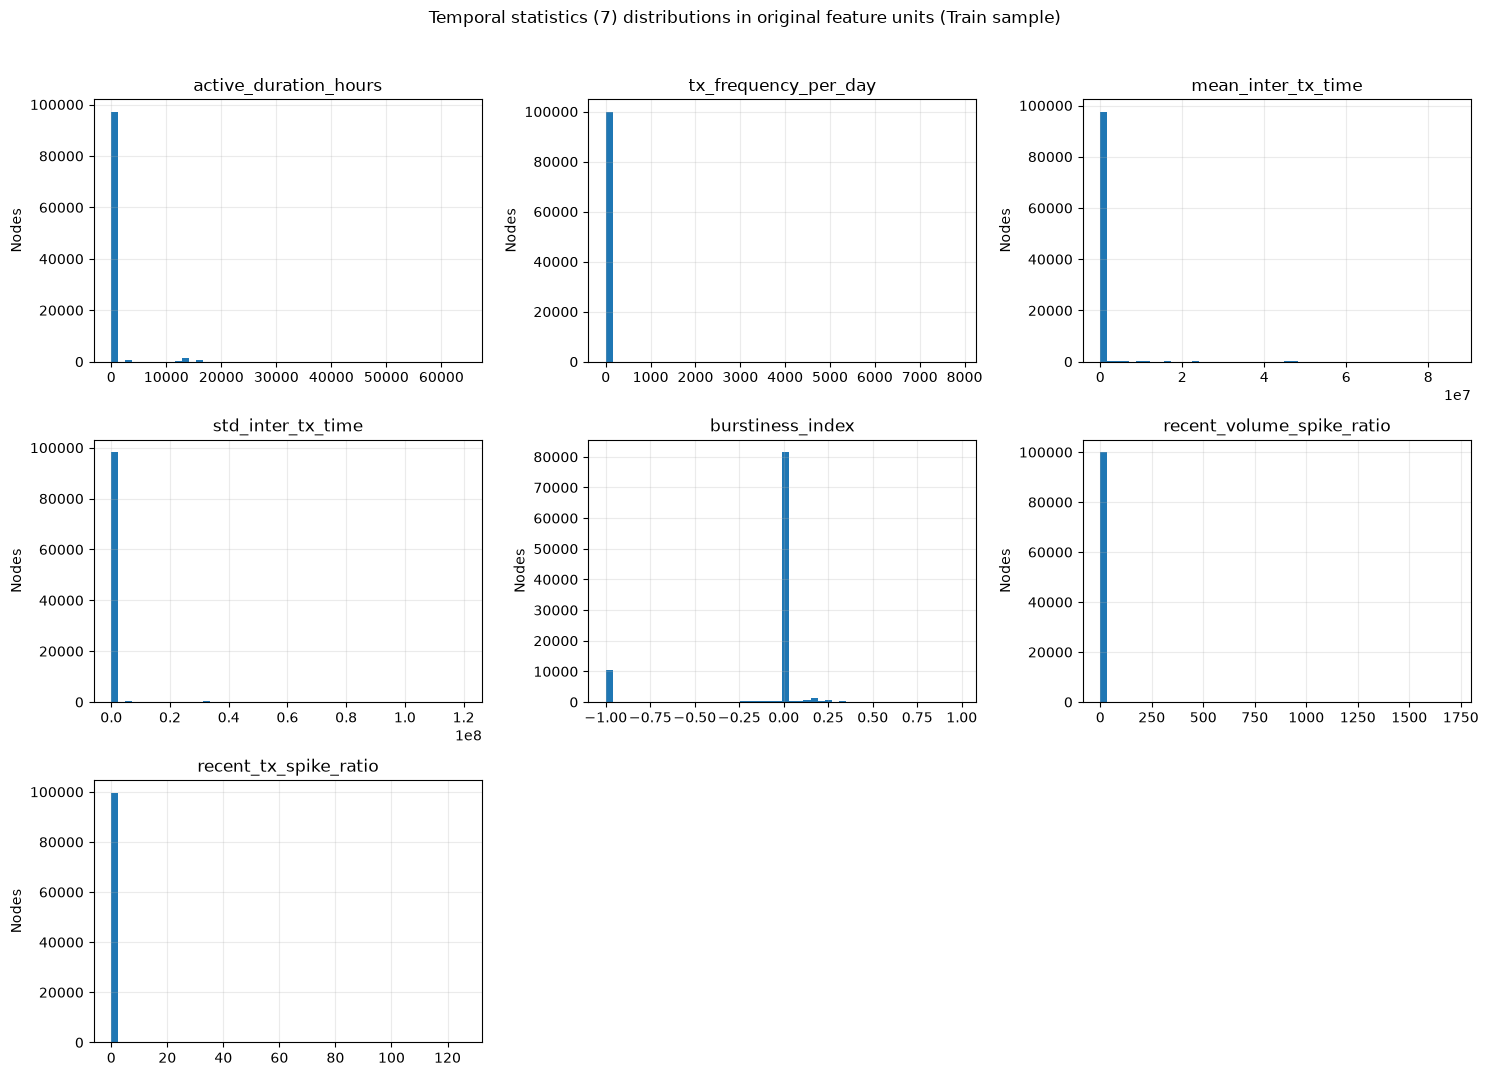

In [31]:
# Histogram theo từng nhóm; dùng sample để giảm thời gian vẽ.
plot_sample = eda_features.sample(
    n=min(100_000, len(eda_features)),
    random_state=42
)

for group_name, columns in feature_groups.items():
    ncols = 3
    nrows = int(np.ceil(len(columns) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.5 * nrows))
    axes = np.array(axes).reshape(-1)

    for ax, col in zip(axes, columns):
        values = pd.to_numeric(plot_sample[col], errors="coerce")
        values = values.replace([np.inf, -np.inf], np.nan).dropna()
        ax.hist(values, bins=50)
        ax.set_title(col)
        ax.set_ylabel("Nodes")

    for ax in axes[len(columns):]:
        ax.set_visible(False)

    fig.suptitle(f"{group_name} distributions in original feature units (Train sample)", y=1.02)
    fig.tight_layout()
    plt.show()

## 6. Graph structure analysis

Các snapshot là đồ thị giao dịch có hướng; cạnh đi từ `from_address` sang `to_address`, và các giao dịch của cùng cặp địa chỉ có hướng được gộp thành một cạnh. `in_degree`/`out_degree` trong feature table đếm số giao dịch, còn `unique_*_neighbors` đếm số đối tác khác nhau.

,nodes,directed_edges,eval_nodes,ego_nodes_processed
split,,,,
train,1016762,1064255,111,1011915
val,1528608,1632692,124,1522530
test,1791594,1923360,125,1784558


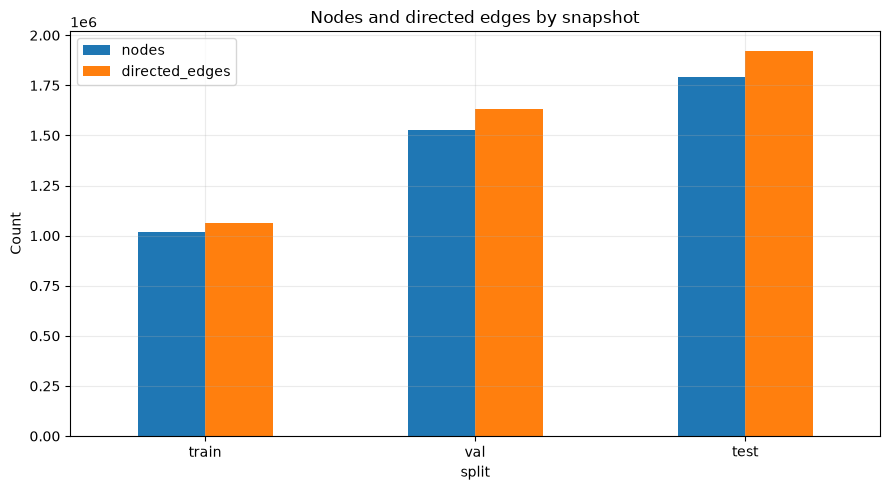

In [32]:
graph_rows = []
for split in SPLITS:
    report_split = graph_report["splits"][split]
    graph_rows.append({
        "split": split,
        "nodes": report_split["nodes"],
        "directed_edges": report_split["directed_edges"],
        "eval_nodes": report_split["eval_nodes"],
        "ego_nodes_processed": report_split["topology"]["ego_nodes_processed"],
    })

graph_summary = pd.DataFrame(graph_rows).set_index("split")
display(graph_summary)

graph_summary[["nodes", "directed_edges"]].plot(kind="bar", title="Nodes and directed edges by snapshot")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

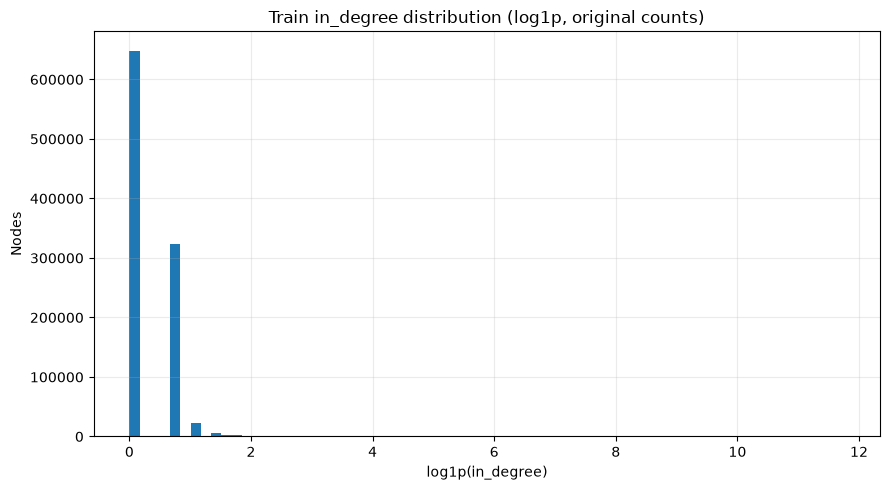

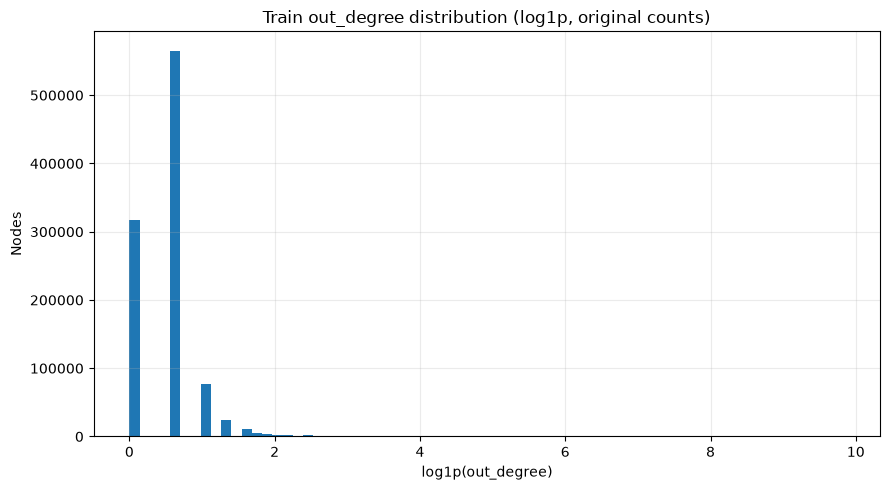

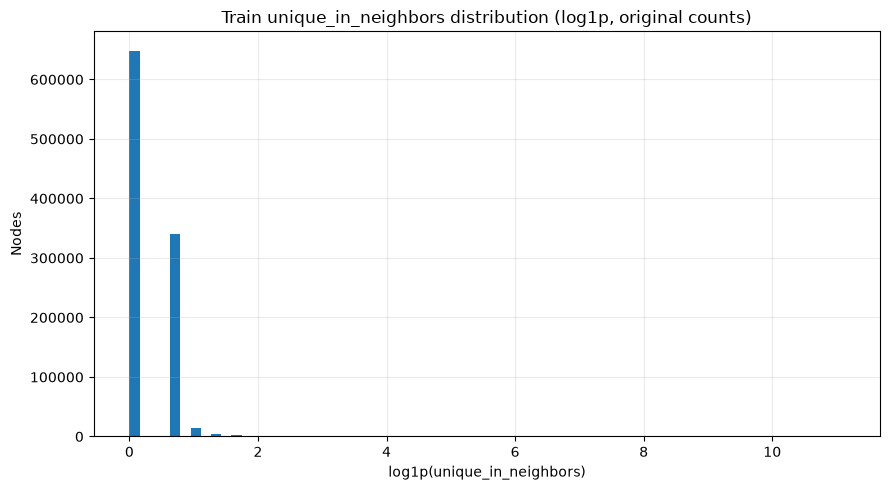

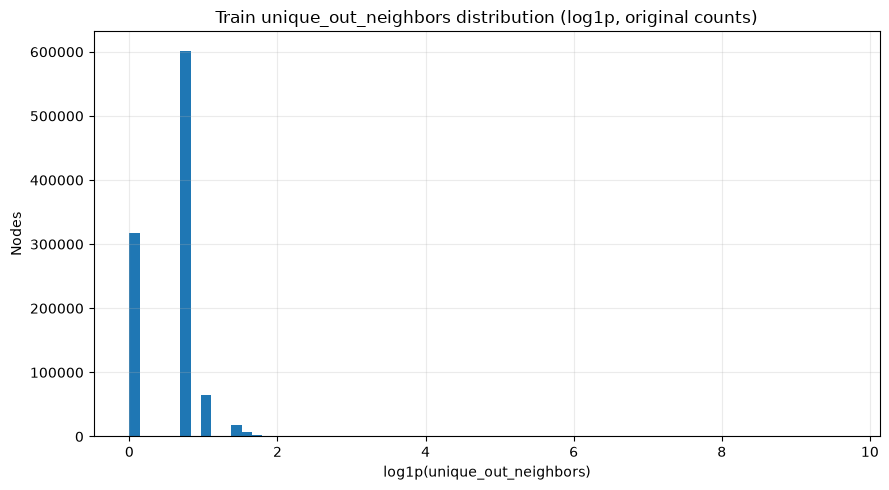

Train local_ego_density summary (original [0,1] scale):


,local_ego_density
count,1.016762e+06
mean,4.658258e-01
std,9.085529e-02
min,0.000000e+00
50%,5.000000e-01
90%,5.000000e-01
95%,5.000000e-01
99%,5.000000e-01
max,1.000000e+00


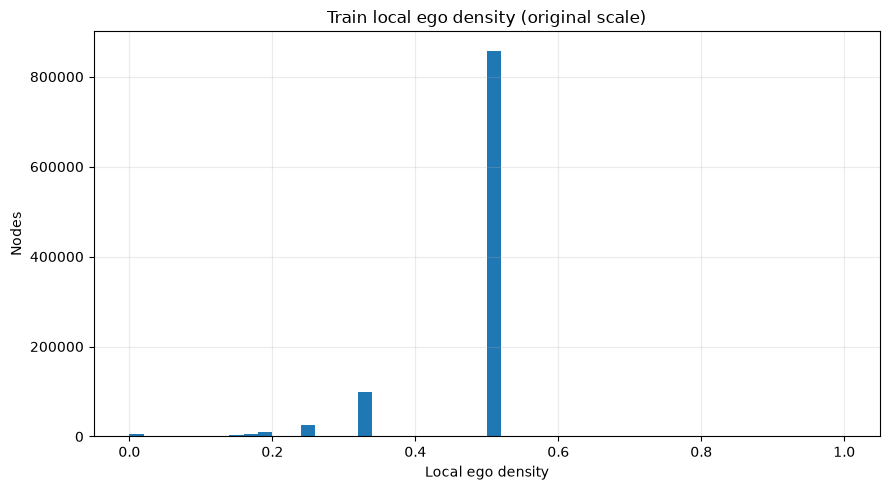

In [33]:
# Degree distributions từ topology features đã khôi phục về đơn vị gốc.
for col in ["in_degree", "out_degree", "unique_in_neighbors", "unique_out_neighbors"]:
    values = pd.to_numeric(eda_features[col], errors="coerce").dropna()
    plt.figure()
    plt.hist(np.log1p(values.clip(lower=0)), bins=70)
    plt.title(f"Train {col} distribution (log1p, original counts)")
    plt.xlabel(f"log1p({col})")
    plt.ylabel("Nodes")
    plt.tight_layout()
    plt.show()

density = pd.to_numeric(
    eda_features["local_ego_density"], errors="coerce"
).dropna()

print("Train local_ego_density summary (original [0,1] scale):")
display(density.describe(percentiles=[.5, .9, .95, .99]).to_frame())

plt.figure()
plt.hist(density, bins=50, range=(0, 1))
plt.title("Train local ego density (original scale)")
plt.xlabel("Local ego density")
plt.ylabel("Nodes")
plt.tight_layout()
plt.show()

## 7. Temporal behavior analysis

Chuỗi thời gian có kích thước `(N, 10, 8)`. Do nguồn dữ liệu là bốn khoảng lấy mẫu thưa, các cửa sổ không có giao dịch quan sát được không thể mặc nhiên diễn giải là tài khoản không hoạt động trên Ethereum trong toàn bộ khoảng đó.

In [34]:
temporal_rows = []
for split in SPLITS:
    report_split = feature_report["splits"][split]
    coverage = report_split.get("temporal_window_coverage", [])
    for item in coverage:
        temporal_rows.append({
            "split": split,
            "window_index": item.get("window_index"),
            "start_utc": item.get("start_utc"),
            "end_utc": item.get("end_utc"),
            "has_observed_transactions": item.get("has_observed_transactions"),
        })

temporal_coverage = pd.DataFrame(temporal_rows)
display(temporal_coverage)
if not temporal_coverage.empty:
    coverage_counts = temporal_coverage.groupby("split")["has_observed_transactions"].agg(
        observed_windows="sum", total_windows="count"
    )
    display(coverage_counts)

,split,window_index,start_utc,end_utc,has_observed_transactions
0,train,0,2024-03-04T17:53:23+00:00,2024-03-05T17:53:23+00:00,False
1,train,1,2024-03-05T17:53:23+00:00,2024-03-06T17:53:23+00:00,False
2,train,2,2024-03-06T17:53:23+00:00,2024-03-07T17:53:23+00:00,False
3,train,3,2024-03-07T17:53:23+00:00,2024-03-08T17:53:23+00:00,False
4,train,4,2024-03-08T17:53:23+00:00,2024-03-09T17:53:23+00:00,False
5,train,5,2024-03-09T17:53:23+00:00,2024-03-10T17:53:23+00:00,False
6,train,6,2024-03-10T17:53:23+00:00,2024-03-11T17:53:23+00:00,False
7,train,7,2024-03-11T17:53:23+00:00,2024-03-12T17:53:23+00:00,True
8,train,8,2024-03-12T17:53:23+00:00,2024-03-13T17:53:23+00:00,True
9,train,9,2024-03-13T17:53:23+00:00,2024-03-14T17:53:23+00:00,True


,observed_windows,total_windows
split,,
test,10,10
train,3,10
val,10,10


In [35]:
for split in SPLITS:
    path = FEATURE_DIR / split / "temporal.pt"
    obj = torch.load(path, map_location="cpu", weights_only=False)

    sequence = obj["sequence"]
    print(
        split,
        "sequence shape:", tuple(sequence.shape),
        "dtype:", sequence.dtype,
        "sequence columns:", obj["sequence_columns"]
    )

train sequence shape: (1016762, 10, 8) dtype: torch.float32 sequence columns: ['tx_in_count', 'tx_out_count', 'val_in_sum', 'val_out_sum', 'val_max', 'unique_counterparties', 'avg_gas_price', 'mean_inter_arrival_time']
val sequence shape: (1528608, 10, 8) dtype: torch.float32 sequence columns: ['tx_in_count', 'tx_out_count', 'val_in_sum', 'val_out_sum', 'val_max', 'unique_counterparties', 'avg_gas_price', 'mean_inter_arrival_time']
test sequence shape: (1791594, 10, 8) dtype: torch.float32 sequence columns: ['tx_in_count', 'tx_out_count', 'val_in_sum', 'val_out_sum', 'val_max', 'unique_counterparties', 'avg_gas_price', 'mean_inter_arrival_time']


## 8. Temporal and inductive split analysis

Tỷ lệ 70/15/15 được tính theo transaction rows. Holdout 10% là mẫu địa chỉ được chọn ngẫu nhiên từ các địa chỉ có trong tập dữ liệu; nó không đồng nghĩa toàn bộ holdout là các địa chỉ lần đầu xuất hiện trong tương lai. Validation/Test snapshots sử dụng lịch sử tích lũy đến cutoff tương ứng; cần phân biệt điều này với việc chỉ lấy giao dịch phát sinh trong riêng split.


,split,transactions,ratio,cutoff_utc
0,train,1833120,0.700039,2024-03-14T17:53:23+00:00
1,val,392844,0.150021,2024-03-22T06:50:23+00:00
2,test,392633,0.149940,2024-03-29T18:49:23+00:00


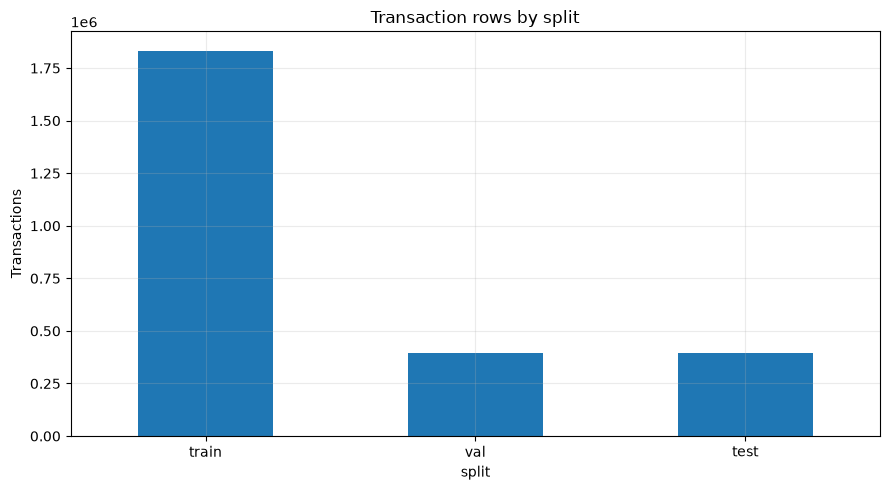

Unique addresses: 1791594
Holdout addresses: 179160
Actual holdout ratio: 0.10000033489730374
Holdout active in test: 32671
Known phishing by period: {'train': 123, 'val': 1, 'test': 1}


In [36]:
split_rows = []
for split, item in split_report["period_partitions"].items():
    split_rows.append({
        "split": split,
        "transactions": item["rows"],
        "ratio": split_report["actual_ratios"][split],
        "cutoff_utc": split_report["cutoffs"][f"T_{split}_utc"],
    })

split_summary = pd.DataFrame(split_rows)
display(split_summary)

split_summary.set_index("split")["transactions"].plot(kind="bar", title="Transaction rows by split")
plt.ylabel("Transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

address_summary = split_report["address_split_summary"]
print("Unique addresses:", address_summary["unique_addresses"])
print("Holdout addresses:", address_summary["inductive_holdout_addresses"])
print("Actual holdout ratio:", address_summary["inductive_holdout_ratio_actual"])
print("Holdout active in test:", address_summary["inductive_holdout_active_in_test"])
print("Known phishing by period:", address_summary["known_phishing_by_period"])

## 9. Leakage audit and rebuilt artifact validation

Phần này đọc kết quả `audit_splits.py` và kiểm tra lại các tensor được tạo sau lần rebuild TV1-04/TV1-05. PASS của split audit xác nhận các điều kiện partition/cutoff và không có train-graph holdout-edge violation theo audit hiện tại; nó **không tự chứng minh** mọi phép tính feature history đều không có future leakage.


**Lưu ý về đường dẫn:** validation đọc sáu graph features từ `data/processed/graphs/{split}/nodes.parquet`. Không đọc chúng từ `data/processed/features/{split}/nodes.parquet`, vì file đó được tạo trước bước graph enrichment và các cột topology tại đó có thể vẫn là null.


In [37]:
# Leakage audit
if leakage_report is None:
    print(
        "Không tìm thấy leakage_audit_report.json. "
        "Chạy: python -m src.pipeline.audit_splits"
    )
else:
    leakage_status = leakage_report.get("status")
    print("Leakage audit status:", leakage_status)
    display(pd.json_normalize(leakage_report).T.rename(columns={0: "value"}))
    assert leakage_status == "PASS", (
        f"Leakage audit chưa PASS: {leakage_status}"
    )

# Artifact quality validation
# Lưu ý: graph_builder ghi node table sau graph enrichment vào GRAPH_DIR,
# còn FEATURE_DIR chứa node table trước khi bổ sung 6 graph topology features.
GRAPH_FEATURES = [
    "in_degree",
    "out_degree",
    "unique_in_neighbors",
    "unique_out_neighbors",
    "neighbor_repeat_ratio",
    "local_ego_density",
]

quality_rows = []

for split in SPLITS:
    graph_nodes_path = GRAPH_DIR / split / "nodes.parquet"
    feature_sequence_path = FEATURE_DIR / split / "temporal.pt"
    graph_path = GRAPH_DIR / split / f"snapshot_{split}.pt"

    if not graph_nodes_path.exists():
        raise FileNotFoundError(f"Missing graph-enriched nodes: {graph_nodes_path}")
    if not feature_sequence_path.exists():
        raise FileNotFoundError(f"Missing temporal sequence: {feature_sequence_path}")
    if not graph_path.exists():
        raise FileNotFoundError(f"Missing graph snapshot: {graph_path}")

    # IMPORTANT: read graph-enriched node table, not pre-graph FEATURE_DIR table.
    nodes = pd.read_parquet(graph_nodes_path)
    graph = torch.load(
        graph_path, map_location="cpu", weights_only=False
    )
    temporal = torch.load(
        feature_sequence_path, map_location="cpu", weights_only=False
    )
    sequence = temporal["sequence"]

    missing_graph_columns = [
        col for col in GRAPH_FEATURES if col not in nodes.columns
    ]
    assert not missing_graph_columns, (
        f"Missing graph feature columns in {split}: {missing_graph_columns}"
    )

    graph_feature_nulls = int(
        nodes[GRAPH_FEATURES].isna().sum().sum()
    )

    graph_x_finite = bool(torch.isfinite(graph.x).all())
    edge_attr_finite = bool(torch.isfinite(graph.edge_attr).all())
    sequence_finite = bool(torch.isfinite(sequence).all())

    row = {
        "split": split,
        "nodes_parquet": len(nodes),
        "graph_nodes": int(graph.x.shape[0]),
        "graph_edges": int(graph.edge_index.shape[1]),
        "graph_feature_nulls": graph_feature_nulls,
        "x_shape": tuple(graph.x.shape),
        "edge_attr_shape": tuple(graph.edge_attr.shape),
        "sequence_shape": tuple(sequence.shape),
        "graph_x_finite": graph_x_finite,
        "edge_attr_finite": edge_attr_finite,
        "sequence_finite": sequence_finite,
    }
    quality_rows.append(row)

    assert len(nodes) == graph.x.shape[0], (
        f"Node count mismatch: {split}"
    )
    assert graph.x.shape[1] == 25, (
        f"Expected 25 node features: {split}"
    )
    assert graph.edge_attr.shape[1] == 5, (
        f"Expected 5 edge features: {split}"
    )
    assert tuple(sequence.shape) == (len(nodes), 10, 8), (
        f"Sequence shape mismatch: {split}; got {tuple(sequence.shape)}"
    )
    assert graph_feature_nulls == 0, (
        f"Graph-enriched node table contains null graph features: {split}"
    )
    assert graph_x_finite, f"graph.x contains NaN/Inf: {split}"
    assert edge_attr_finite, f"edge_attr contains NaN/Inf: {split}"
    assert sequence_finite, f"temporal sequence contains NaN/Inf: {split}"

quality_check = pd.DataFrame(quality_rows).set_index("split")
display(quality_check)
print("Artifact shape/null/finite validation: PASS")


Leakage audit status: PASS


,value
status,PASS
holdout_addresses,179160
train_graph_rows,1475581
train_graph_holdout_edge_violations,0
train_graph_max_timestamp,1710438803
notes,"[This audit verifies chronology, train holdout..."
partition_bounds_unix.train.min,1479343893
partition_bounds_unix.train.max,1710438803
partition_bounds_unix.train.rows,1833120
partition_bounds_unix.val.min,1710439103


,nodes_parquet,graph_nodes,graph_edges,graph_feature_nulls,x_shape,edge_attr_shape,sequence_shape,graph_x_finite,edge_attr_finite,sequence_finite
split,,,,,,,,,,
train,1016762,1016762,1064255,0,"(1016762, 25)","(1064255, 5)","(1016762, 10, 8)",True,True,True
val,1528608,1528608,1632692,0,"(1528608, 25)","(1632692, 5)","(1528608, 10, 8)",True,True,True
test,1791594,1791594,1923360,0,"(1791594, 25)","(1923360, 5)","(1791594, 10, 8)",True,True,True


Artifact shape/null/finite validation: PASS


## 10. Key findings and limitations

### Findings supported by the current artifacts
- Dataset mẫu gồm bốn transaction Parquet với tổng 2.618.597 giao dịch.
- Address registry ghi nhận 1.791.594 địa chỉ duy nhất; 125 địa chỉ đã biết phishing và 1.791.469 địa chỉ chưa được gán nhãn.
- Không có verified-normal label trong registry hiện tại.
- Ba graph snapshots chứa lần lượt 1.016.762 / 1.528.608 / 1.791.594 node và 1.064.255 / 1.632.692 / 1.923.360 directed edges.
- Sau rebuild TV1-04/TV1-05, 25 node features được lưu trong graph tensors; sáu graph features không còn null trong các split theo kiểm tra chất lượng mới nhất.
- Temporal sequence có kích thước `(N, 10, 8)` cho cả ba split.
- Scalers được fit trên Train theo báo cáo pipeline.
- Split theo transaction rows gần đúng 70/15/15; holdout địa chỉ xấp xỉ 10%; leakage audit hiện tại báo PASS.

### Limitations that must be stated
- Bốn khoảng dữ liệu là sparse temporal samples, không phải lịch sử Ethereum liên tục.
- `-1` là unlabeled, không phải normal.
- Giao dịch liên quan đến địa chỉ phishing không tự động là giao dịch phishing.
- Không có verified-normal labels nên chưa thể tuyên bố đây là bộ dữ liệu supervised binary hoàn chỉnh hoặc báo cáo các metric phân loại nhị phân như thể có ground truth âm đáng tin cậy.
- Holdout ngẫu nhiên trên địa chỉ quan sát được không phải cohort địa chỉ mới thực sự trong tương lai.
- Leakage audit PASS kiểm tra các điều kiện đã được lập trình; chưa chứng minh mọi phép tính feature history không có future leakage.
- Báo cáo này mô tả dữ liệu và cấu trúc; chưa chứng minh hiệu năng phát hiện bất thường của mô hình.


In [38]:
# Compact reproducibility summary
summary = {
    "transaction_rows": int(split_report["input"]["total_transactions"]),
    "unique_addresses": int(address_report["summary"]["unique_addresses_in_sample"]),
    "known_phishing_addresses": int(address_report["summary"]["known_phishing_addresses_found_in_sample"]),
    "verified_normal_addresses": int((registry["label"] == 0).sum()),
    "unlabeled_addresses": int((registry["label"] == -1).sum()),
    "leakage_audit_status": leakage_report.get("status") if leakage_report else "not_available",
    "splits": {
        split: {
            "transactions": int(split_report["period_partitions"][split]["rows"]),
            "nodes": int(graph_report["splits"][split]["nodes"]),
            "directed_edges": int(graph_report["splits"][split]["directed_edges"]),
        }
        for split in SPLITS
    },
}
print(json.dumps(summary, indent=2))

{
  "transaction_rows": 2618597,
  "unique_addresses": 1791594,
  "known_phishing_addresses": 125,
  "verified_normal_addresses": 0,
  "unlabeled_addresses": 1791469,
  "leakage_audit_status": "PASS",
  "splits": {
    "train": {
      "transactions": 1833120,
      "nodes": 1016762,
      "directed_edges": 1064255
    },
    "val": {
      "transactions": 392844,
      "nodes": 1528608,
      "directed_edges": 1632692
    },
    "test": {
      "transactions": 392633,
      "nodes": 1791594,
      "directed_edges": 1923360
    }
  }
}
